# 🧠 MODEL LSTM (FINAL) — Prediksi Volatilitas Return Saham
## Tesis: Pemodelan Prediksi Volatilitas Return Saham Sektor Energi LQ45
**Ilda Nurida — 6032251068 | Pembimbing: Dr. Ir. Ahmad Saikhu, S.Si, MT.**

### 🔧 Versi final — konsisten dgn XGBoost
- **Set fitur identik (28)** dgn XGBoost final (termasuk 8 fitur sentimen) → perbandingan RM-3 sah.
- Arsitektur LSTM 2-lapis (64→32) + BatchNorm + Dropout, **lookback=10**, `shuffle=False`.
- Evaluasi pada **skala volatilitas asli** (inverse-transform). Reprodusibel (seed tetap).
- Output → `lstm_best_{emiten}.keras`, `tabel_evaluasi_lstm.csv`, `hasil_prediksi_lstm.csv`, gambar.

In [2]:
import os, datetime
from pathlib import Path
import pandas as pd

# ════════════════════════════════════════════════════════════════════
#  PATH KANONIK + IO UTILITAS — IDENTIK DI SEMUA NOTEBOOK
#  (otomatis disisipkan oleh proses audit path)
# ════════════════════════════════════════════════════════════════════
ROOT_HARDCODED = Path(r'E:\DATA PENTING ILDA NURIDA\DOKUMEN\KULIAH\S2 2025\THESIS'
                      r'\Penelitian\TESIS_PEMODELAN PREDIKSI VOLATILITAS RETURN SAHAM_2026')

def cari_root():
    p = Path(os.getcwd())
    for _ in range(8):
        if (p / '03_dataset').exists():
            return p
        p = p.parent
    if ROOT_HARDCODED.exists():
        return ROOT_HARDCODED
    raise FileNotFoundError('ROOT proyek (folder berisi 03_dataset/) tidak ditemukan.')

ROOT = cari_root()
DIR_RAW       = ROOT / '03_dataset' / 'raw'
DIR_PROCESSED = ROOT / '03_dataset' / 'processed'
DIR_FINAL     = ROOT / '03_dataset' / 'final'
DIR_MODEL     = ROOT / '04_model'
DIR_TABEL     = ROOT / '06_dokumen_tesis' / 'tabel'
for _d in (DIR_RAW, DIR_PROCESSED, DIR_FINAL, DIR_TABEL):
    _d.mkdir(parents=True, exist_ok=True)

# Nama file kanonik
F_HARGA    = 'harga_saham_raw.csv'         # DIR_RAW
F_TEKNIKAL = 'technical_features.csv'      # DIR_PROCESSED (satu-satunya lokasi)
F_SENTIMEN = 'skor_sentimen_harian.csv'    # DIR_PROCESSED (nama tunggal)
F_GABUNGAN = 'dataset_gabungan_X1X2Y.csv'  # DIR_FINAL

def muat_csv(path, **kw):
    """LOAD + log sumber absolut. Error eksplisit bila tak ada (TANPA fallback diam-diam)."""
    path = Path(path)
    if not path.exists():
        raise FileNotFoundError(f'File TIDAK ADA: {path.resolve()}\n'
                                f'   -> Tahap sebelumnya belum menyimpan ke lokasi kanonik ini.')
    df = pd.read_csv(path, **kw)
    print(f'LOAD  : {path.resolve()}  ({len(df):,} baris x {df.shape[1]} kolom)')
    return df

def simpan_csv(df, path, index=False, **kw):
    """SAVE + log path absolut + WARNING bila menimpa file lama."""
    path = Path(path); path.parent.mkdir(parents=True, exist_ok=True)
    if path.exists():
        mt = datetime.datetime.fromtimestamp(path.stat().st_mtime).strftime('%Y-%m-%d %H:%M')
        print(f'OVERWRITE: {path.resolve()}  (file lama {mt} ditimpa)')
    df.to_csv(path, index=index, encoding='utf-8-sig', **kw)
    print(f'SAVE  : {path.resolve()}  ({len(df):,} baris)')

print(f'ROOT : {ROOT.resolve()}')
print(f'  RAW={DIR_RAW.name}/  PROCESSED={DIR_PROCESSED.name}/  FINAL={DIR_FINAL.name}/')


ROOT : E:\DATA PENTING ILDA NURIDA\DOKUMEN\KULIAH\S2 2025\THESIS\Penelitian\TESIS_PEMODELAN PREDIKSI VOLATILITAS RETURN SAHAM_2026
  RAW=raw/  PROCESSED=processed/  FINAL=final/


## ⚙️ CELL 1 — Import, Konfigurasi, Feature Set

In [3]:
# ==============================================================================
# CELL 1 — KONFIGURASI AWAL LSTM (REVISED FINAL)
# ==============================================================================

import os
import random
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf

from tensorflow.keras import Sequential
from tensorflow.keras.layers import Input, LSTM, Dense, Dropout
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau, ModelCheckpoint
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

warnings.filterwarnings('ignore')
os.environ['TF_CPP_MIN_LOG_LEVEL'] = '3'


# ==============================================================================
# REPRODUCIBILITY
# ==============================================================================
SEED = 42
np.random.seed(SEED)
random.seed(SEED)
tf.random.set_seed(SEED)


# ==============================================================================
# PLOT STYLE
# ==============================================================================
plt.rcParams.update({
    'font.family': 'Times New Roman',
    'font.size': 11,
    'figure.dpi': 150
})


# ==============================================================================
# HELPER FUNCTION (FIX NameError muat_csv)
# ==============================================================================
def muat_csv(path):
    """
    Load CSV dengan fallback encoding.
    """
    path = Path(path)

    if not path.exists():
        raise FileNotFoundError(f'File tidak ditemukan: {path}')

    try:
        return pd.read_csv(path, encoding='utf-8-sig')
    except UnicodeDecodeError:
        try:
            return pd.read_csv(path, encoding='latin1')
        except:
            return pd.read_csv(path)


# ==============================================================================
# ROOT PATH
# ==============================================================================
ROOT = Path.cwd()

for _ in range(6):
    if (ROOT / '03_dataset').exists():
        break
    ROOT = ROOT.parent

if not (ROOT / '03_dataset').exists():
    ROOT = Path(
        r'E:\DATA PENTING ILDA NURIDA\DOKUMEN\KULIAH\S2 2025\THESIS\Penelitian\TESIS_PEMODELAN PREDIKSI VOLATILITAS RETURN SAHAM_2026'
    )


# ==============================================================================
# DIRECTORY
# ==============================================================================
DIR_FINAL  = ROOT / '03_dataset' / 'final'
DIR_MODEL  = ROOT / '04_model' / 'lstm'
DIR_TABEL  = ROOT / '06_dokumen_tesis' / 'tabel'
DIR_GAMBAR = ROOT / '06_dokumen_tesis' / 'gambar' / 'model'

for folder in [DIR_MODEL, DIR_TABEL, DIR_GAMBAR]:
    folder.mkdir(parents=True, exist_ok=True)


# ==============================================================================
# PARAMETER GLOBAL
# ==============================================================================
URUTAN_EMITEN = [
    'ADRO', 'ADMR', 'ITMG',
    'PTBA', 'MEDC', 'AKRA', 'PGAS'
]

# FIX AUDIT BUG #1 — TARGET Y HARUS FORECAST (t+1), BUKAN NOWCAST (t)
# 'Volatilitas' (nowcast) hanya basis perhitungan lag di PREP_01; kolom
# forecast sesungguhnya adalah 'Volatilitas_Target' (sudah di-shift -1).
# Memakai 'Volatilitas' di sini adalah PENYEBAB UTAMA R2 negatif yang
# ditemukan sebelumnya (lihat FIX #2 di bawah untuk penyebab keduanya).
KOLOM_Y = 'Volatilitas_Target'

LOOKBACK = 10
EPOCHS   = 100
BATCH    = 16
PATIENCE = 20   # turun dari 40 → lebih optimal


# ==============================================================================
# FEATURE INPUT
# ==============================================================================
# FIX AUDIT BUG #2 — 'Volatilitas_Return' DIHAPUS dari daftar fitur.
# Di pipeline lama, kolom ini adalah DUPLIKAT PERSIS dari 'Volatilitas' (Y
# nowcast) — artinya X memuat Y itu sendiri (leakage langsung). Kolom ini
# sudah tidak ada sama sekali di technical_features.csv v2 (PREP_01),
# sengaja dihapus saat audit. Daftar di bawah PERSIS sama dengan 17 fitur
# final PREP_03 v2 (13 X1 teknikal + 4 X2 sentimen).
KOLOM_X_KANDIDAT = [
    # ── X1 Teknikal (13) ──
    'Log_Return', 'Vol_Lag1', 'Vol_Lag2', 'Vol_Lag3', 'Vol_MA5', 'Vol_STD5',
    'MA5_Ratio', 'MA10_Ratio', 'MA20_Ratio', 'RSI14',
    'Stoch_K', 'Stoch_D', 'Volume_ZScore',
    # ── X2 Sentimen (4) ──
    'Sentiment_Mean', 'Sentiment_Dispersion', 'News_Count', 'Ada_Berita',
]


print('=' * 75)
print('🚀 CONFIG LSTM BERHASIL DIMUAT')
print('=' * 75)
print(f'ROOT       : {ROOT}')
print(f'N EMITEN   : {len(URUTAN_EMITEN)}')
print(f'LOOKBACK   : {LOOKBACK}')
print(f'N FEATURE  : {len(KOLOM_X_KANDIDAT)}')
print('=' * 75)

🚀 CONFIG LSTM BERHASIL DIMUAT
ROOT       : e:\DATA PENTING ILDA NURIDA\DOKUMEN\KULIAH\S2 2025\THESIS\Penelitian\TESIS_PEMODELAN PREDIKSI VOLATILITAS RETURN SAHAM_2026
N EMITEN   : 7
LOOKBACK   : 10
N FEATURE  : 17


## 🔧 CELL 2 — Fungsi Bantu

In [4]:
# ==============================================================================
# CELL — HELPER EVALUASI METRIK (REVISED FINAL)
# ==============================================================================

import numpy as np
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score


def inverse_transform(nilai, scaler_df, kolom=KOLOM_Y):
    """
    Mengembalikan data hasil scaling ke skala asli.
    """
    nilai = np.asarray(nilai, dtype=np.float32).reshape(-1)

    if scaler_df is None or kolom not in scaler_df.index:
        return nilai

    cmin = float(scaler_df.loc[kolom, 'min'])
    cmax = float(scaler_df.loc[kolom, 'max'])

    return nilai * (cmax - cmin) + cmin


def _mape(y, p, eps=1e-8):
    y = np.asarray(y, dtype=np.float32).reshape(-1)
    p = np.asarray(p, dtype=np.float32).reshape(-1)

    mask = np.abs(y) > eps
    if mask.sum() == 0:
        return np.nan

    return float(np.mean(np.abs((y[mask] - p[mask]) / y[mask])) * 100)


def _smape(y, p, eps=1e-8):
    y = np.asarray(y, dtype=np.float32).reshape(-1)
    p = np.asarray(p, dtype=np.float32).reshape(-1)

    denom = np.abs(y) + np.abs(p)
    mask = denom > eps

    if mask.sum() == 0:
        return np.nan

    return float(np.mean(2 * np.abs(p[mask] - y[mask]) / denom[mask]) * 100)


def _qlike(y, p, eps=1e-8):
    """
    QLIKE untuk volatility forecast.
    """
    y = np.maximum(np.asarray(y, dtype=np.float32).reshape(-1), eps)
    p = np.maximum(np.asarray(p, dtype=np.float32).reshape(-1), eps)

    ht = y ** 2
    hp = p ** 2

    return float(np.mean(np.log(hp) + (ht / hp)))


def evaluasi_semua_metrik(y_true, y_pred):
    """
    Evaluasi seluruh metrik.
    """
    y_true = np.asarray(y_true, dtype=np.float32).reshape(-1)
    y_pred = np.asarray(y_pred, dtype=np.float32).reshape(-1)

    rmse = np.sqrt(mean_squared_error(y_true, y_pred))
    mae = mean_absolute_error(y_true, y_pred)
    r2 = r2_score(y_true, y_pred)

    mape = _mape(y_true, y_pred)
    smape = _smape(y_true, y_pred)
    qlike = _qlike(y_true, y_pred)

    return {
        'RMSE': round(float(rmse), 6),
        'MAE': round(float(mae), 6),
        'MAPE (%)': round(mape, 2) if not np.isnan(mape) else np.nan,
        'sMAPE (%)': round(smape, 2) if not np.isnan(smape) else np.nan,
        'R2': round(float(r2), 4),
        'QLIKE': round(float(qlike), 4)
    }


def interpretasi_mape(m):
    if np.isnan(m):
        return 'Tidak Terdefinisi'
    elif m < 10:
        return 'Sangat Baik'
    elif m < 20:
        return 'Baik'
    elif m < 50:
        return 'Cukup'
    else:
        return 'Kurang Baik'


print("✅ Helper evaluasi LSTM berhasil dimuat")

✅ Helper evaluasi LSTM berhasil dimuat


## 📂 CELL 3 — Load Dataset per Emiten (allowlist 28 fitur)

In [5]:
# ==============================================================================
# CELL — LOAD DATASET PANEL PER EMITEN (REVISED FINAL)
# ==============================================================================

dict_train = {}
dict_test = {}
dict_scaler = {}
dict_kolom_x = {}

def safe_read_csv(path):
    try:
        return pd.read_csv(path, encoding='utf-8-sig')
    except:
        return pd.read_csv(path)

print('=' * 85)
print(f'📂 MEMUAT DATASET DARI: {DIR_FINAL.resolve()}')
print('=' * 85)

for emiten in URUTAN_EMITEN:

    p_tr = DIR_FINAL / f'dataset_train_{emiten}.csv'
    p_te = DIR_FINAL / f'dataset_test_{emiten}.csv'
    p_sc = DIR_FINAL / f'scaler_params_{emiten}.csv'

    # =========================
    # VALIDASI FILE
    # =========================
    if not p_tr.exists():
        print(f'⚠️ {emiten}: train file missing')
        continue

    if not p_te.exists():
        print(f'⚠️ {emiten}: test file missing')
        continue

    # =========================
    # LOAD
    # =========================
    df_tr = safe_read_csv(p_tr)
    df_te = safe_read_csv(p_te)

    # =========================
    # DATE CLEANING
    # =========================
    for df in [df_tr, df_te]:
        if 'Date' in df.columns:
            df['Date'] = pd.to_datetime(df['Date'], errors='coerce')

    # =========================
    # FEATURE MATCHING — FIX AUDIT: FAIL-FAST, bukan silent-drop
    # =========================
    # Versi lama diam-diam membuang fitur yang tidak ketemu (mis. akibat
    # PREP_02/03 direvisi tapi notebook ini belum diupdate) — ini yang
    # menyembunyikan drift kolom sampai R2 negatif baru ketahuan di ujung.
    # Sekarang: kalau ADA satu saja fitur KOLOM_X_KANDIDAT yang hilang,
    # notebook berhenti dengan pesan jelas, bukan diam-diam jalan dengan
    # fitur yang lebih sedikit dari yang dikira.
    kolom_x_hilang = [
        c for c in KOLOM_X_KANDIDAT
        if c not in df_tr.columns or c not in df_te.columns
    ]
    if kolom_x_hilang:
        raise ValueError(
            f"❌ {emiten}: fitur X hilang dari dataset_train/test: {kolom_x_hilang}\n"
            f"   Kolom tersedia (train): {df_tr.columns.tolist()}\n"
            f"   → Cek KOLOM_X_KANDIDAT di CELL 1 vs kolom aktual hasil PREP_03 v2."
        )
    kolom_x = list(KOLOM_X_KANDIDAT)

    if KOLOM_Y not in df_tr.columns or KOLOM_Y not in df_te.columns:
        print(f'⚠️ {emiten}: target {KOLOM_Y} missing')
        continue

    # =========================
    # DROP NA
    # =========================
    df_tr = df_tr.dropna(subset=kolom_x + [KOLOM_Y]).reset_index(drop=True)
    df_te = df_te.dropna(subset=kolom_x + [KOLOM_Y]).reset_index(drop=True)

    # Minimal rows untuk LSTM
    if len(df_tr) <= LOOKBACK or len(df_te) <= LOOKBACK:
        print(f'⚠️ {emiten}: data kurang untuk LOOKBACK={LOOKBACK}')
        continue

    # =========================
    # LOAD SCALER
    # =========================
    scaler = None

    if p_sc.exists():
        scaler = pd.read_csv(p_sc, index_col=0)

        if KOLOM_Y not in scaler.index:
            print(f'⚠️ {emiten}: scaler target missing')
            scaler = None

    # =========================
    # STORE
    # =========================
    dict_train[emiten] = df_tr
    dict_test[emiten] = df_te
    dict_scaler[emiten] = scaler
    dict_kolom_x[emiten] = kolom_x

    ada_sentimen = 'Sentiment_Mean' in kolom_x

    print(
        f'✅ {emiten:5s} | '
        f'Train={len(df_tr):4d} | '
        f'Test={len(df_te):4d} | '
        f'Feature={len(kolom_x):2d} | '
        f'Sentimen={"YA" if ada_sentimen else "TIDAK"}'
    )

print('=' * 85)
print(f'Total emiten loaded: {len(dict_train)}/{len(URUTAN_EMITEN)}')
print('=' * 85)

if len(dict_train) == 0:
    raise ValueError("Tidak ada dataset yang berhasil dimuat.")

📂 MEMUAT DATASET DARI: E:\DATA PENTING ILDA NURIDA\DOKUMEN\KULIAH\S2 2025\THESIS\Penelitian\TESIS_PEMODELAN PREDIKSI VOLATILITAS RETURN SAHAM_2026\03_dataset\final
✅ ADRO  | Train= 836 | Test= 209 | Feature=17 | Sentimen=YA
✅ ADMR  | Train= 836 | Test= 209 | Feature=17 | Sentimen=YA
✅ ITMG  | Train= 836 | Test= 209 | Feature=17 | Sentimen=YA
✅ PTBA  | Train= 836 | Test= 209 | Feature=17 | Sentimen=YA
✅ MEDC  | Train= 836 | Test= 209 | Feature=17 | Sentimen=YA
✅ AKRA  | Train= 836 | Test= 209 | Feature=17 | Sentimen=YA
✅ PGAS  | Train= 836 | Test= 209 | Feature=17 | Sentimen=YA
Total emiten loaded: 7/7


## 🔧 CELL 4 — Fungsi Sekuens & Arsitektur LSTM

In [6]:
# ==============================================================================
# CELL — GENERATOR SEQUENCE 3D & MODEL LSTM (FINAL REVISED)
# ==============================================================================

def buat_sekuens(X, y, lookback=LOOKBACK):
    """
    Mengubah data tabular 2D menjadi tensor 3D untuk input LSTM.
    Output:
        X_seq -> (samples, timestep, features)
        y_seq -> target per sequence
    """
    X_arr = np.asarray(X, dtype=np.float32)
    y_arr = np.asarray(y, dtype=np.float32).reshape(-1)

    if len(X_arr) <= lookback:
        raise ValueError(
            f"Jumlah data ({len(X_arr)}) <= LOOKBACK ({lookback}). "
            "Data tidak cukup untuk membuat sequence."
        )

    X_seq = []
    y_seq = []

    for i in range(lookback, len(X_arr)):
        X_seq.append(X_arr[i - lookback:i, :])
        y_seq.append(y_arr[i])

    X_seq = np.array(X_seq, dtype=np.float32)
    y_seq = np.array(y_seq, dtype=np.float32)

    return X_seq, y_seq


def buat_model_lstm(
    n_fitur,
    lookback=LOOKBACK,
    unit1=64,
    unit2=32,
    dropout=0.2,
    recurrent_dropout=0.1,
    lr=1e-4,
    l2_dense=0.0,
):
    """
    Membangun model LSTM untuk prediksi volatilitas saham (v3: fleksibel).
    unit2=None -> hanya 1 layer LSTM (arsitektur lebih sederhana, dipakai
    untuk emiten rawan overfitting seperti AKRA -- lihat GRID_LSTM di bawah).
    """
    reg_dense = tf.keras.regularizers.l2(l2_dense) if l2_dense > 0 else None

    model = Sequential(name='LSTM_Volatility_Model')
    model.add(Input(shape=(lookback, n_fitur)))

    if unit2 is not None:
        model.add(LSTM(unit1, return_sequences=True, recurrent_dropout=recurrent_dropout))
        model.add(Dropout(dropout))
        model.add(LSTM(unit2, return_sequences=False, recurrent_dropout=recurrent_dropout))
        model.add(Dropout(dropout))
    else:
        model.add(LSTM(unit1, return_sequences=False, recurrent_dropout=recurrent_dropout))
        model.add(Dropout(dropout))

    model.add(Dense(16, activation='relu', kernel_regularizer=reg_dense))
    model.add(Dense(1, activation='softplus'))

    optimizer = Adam(learning_rate=lr)
    model.compile(optimizer=optimizer, loss='mse', metrics=['mae'])
    return model


# FIX AUDIT v3 -- grid kecil kandidat arsitektur per emiten (bukan cuma 1
# konfigurasi tetap untuk semua emiten). Dipilih berdasarkan val_loss
# terbaik di CELL 5, meniru semangat RandomizedSearchCV yang sudah dipakai
# XGBoost, versi ringan (3 kandidat) karena training LSTM jauh lebih mahal.
# Temuan yang melatarbelakangi: AKRA overfitting parah (val_loss naik tajam
# sejak epoch awal, EarlyStopping di epoch 21, R2=-5.53) padahal fitur X1/X2
# identik dengan emiten lain yang berhasil baik di XGBoost (R2 AKRA=0.83) --
# indikasi arsitektur 64->32 unit terlalu kompleks utk ~840 sekuens training.
GRID_LSTM = [
    {'nama': 'A_baseline',          'unit1': 64, 'unit2': 32,  'dropout': 0.2, 'lr': 1e-4, 'l2_dense': 0.0},
    {'nama': 'B_sederhana',         'unit1': 32, 'unit2': 16,  'dropout': 0.3, 'lr': 1e-4, 'l2_dense': 0.001},
    {'nama': 'C_regularisasi_kuat', 'unit1': 16, 'unit2': None, 'dropout': 0.3, 'lr': 5e-5, 'l2_dense': 0.01},
]


print("=" * 75)
print("Sequence Generator & Model LSTM v3 (arsitektur fleksibel) dimuat")
print(f"LOOKBACK        : {LOOKBACK}")
print(f"Kandidat grid   : {len(GRID_LSTM)} konfigurasi per emiten (dipilih via val_loss)")
for g in GRID_LSTM:
    arsi = f"LSTM({g['unit1']})->LSTM({g['unit2']})" if g['unit2'] else f"LSTM({g['unit1']}) saja"
    print(f"   - {g['nama']:<20s}: {arsi}, dropout={g['dropout']}, lr={g['lr']}, l2={g['l2_dense']}")
print("Output          : Positive Volatility (softplus)")
print("=" * 75)


✅ Sequence Generator & Model LSTM berhasil dimuat
📐 LOOKBACK      : 10
📐 Architecture  : LSTM(64) → LSTM(32) → Dense(16) → Dense(1)
📐 Output        : Positive Volatility (softplus)


In [7]:
# ==============================================================================
# SETUP TENSORFLOW UNTUK TRAINING LSTM
# ==============================================================================

import tensorflow as tf

# Gunakan graph execution (default TensorFlow, lebih cepat)
tf.config.run_functions_eagerly(False)

# Bersihkan graph/session lama
tf.keras.backend.clear_session()

# Optional: wrapper prediksi untuk mengurangi retracing warning
@tf.function(reduce_retracing=True)
def prediksi_cepat(model, x):
    return model(x, training=False)

print("=" * 70)
print("✅ TensorFlow session berhasil diinisialisasi")
print("✅ Graph mode aktif")
print("✅ Fast prediction function aktif")
print("=" * 70)


✅ TensorFlow session berhasil diinisialisasi
✅ Graph mode aktif
✅ Fast prediction function aktif


In [8]:
for emiten in URUTAN_EMITEN:
    if emiten in dict_train:
        print(emiten)
        print(dict_train[emiten].columns.tolist())
        break

ADRO
['Date', 'Emiten', 'Log_Return', 'Vol_Lag1', 'Vol_Lag2', 'Vol_Lag3', 'Vol_MA5', 'Vol_STD5', 'MA5_Ratio', 'MA10_Ratio', 'MA20_Ratio', 'RSI14', 'Stoch_K', 'Stoch_D', 'Volume_ZScore', 'Sentiment_Mean', 'Sentiment_Dispersion', 'News_Count', 'Ada_Berita', 'Volatilitas_Target']


## 🎯 CELL 5 — Training, Prediksi & Evaluasi per Emiten (skala asli)

In [9]:
import os, warnings
# Mengubah level log dari 3 menjadi 4 untuk memblokir warning level kompilasi grafik
os.environ['TF_CPP_MIN_LOG_LEVEL'] = '3' 
os.environ['TF_ENABLE_ONEDNN_OPTS'] = '0'

import tensorflow as tf
# Meredam semua pesan peringatan internal modul TensorFlow di konsol Jupyter
tf.get_logger().setLevel('ERROR')
tf.autograph.set_verbosity(0)
warnings.filterwarnings('ignore', category=UserWarning, module='tensorflow')

# ==============================================================================
# [SUNTIKAN PENGAMAN] FUNGSI PREDIKSI TEROPTIMALISASI PENAHAN RE-TRACING WARNING
# ==============================================================================
@tf.function(reduce_retracing=True)
def prediksi_cepat(model_obj, input_tensor):
    """Memaksa TensorFlow mengunci grafik komputasi evaluasi agar bebas warning."""
    return model_obj(input_tensor, training=False)

# ==============================================================================
# CELL — LOOP TRAINING OTOMATIS MODEL DEEP LEARNING LSTM (7 EMITEN)
# ==============================================================================

dict_model_lstm, dict_history, dict_hasil_lstm = {}, {}, {}
list_eval = []

print('='*85)
print(' 🎯 PROSES PELATIHAN AUTOMATED TRAINING MODEL LSTM — SEKTOR ENERGI')
print('='*85)

for emiten in URUTAN_EMITEN:
    if emiten not in dict_train: 
        continue
        
    df_tr, df_te = dict_train[emiten], dict_test[emiten]
    kolom_x, scaler = dict_kolom_x[emiten], dict_scaler[emiten]
    n_fitur = len(kolom_x)

    # Ekstraksi array mentah numpy dari DataFrame
    X_tr = df_tr[kolom_x].values.astype(float)
    y_tr = df_tr[KOLOM_Y].values.astype(float)
    X_te = df_te[kolom_x].values.astype(float)
    y_te = df_te[KOLOM_Y].values.astype(float)
    
    # Pembentukan Tensor 3D [Samples, Timesteps, Features]
    Xs_tr, ys_tr = buat_sekuens(X_tr, y_tr, LOOKBACK)
    Xs_te, ys_te = buat_sekuens(X_te, y_te, LOOKBACK)

    # Validasi kelayakan jumlah sampel minimum bursa terhadap ukuran Batch
    if len(Xs_tr) < BATCH * 2:
        print(f'  ⚠️  {emiten:5s}: Sampel data latih terlalu sedikit ({len(Xs_tr)}), melewati emiten ini.')
        continue

    # Pembersihan grafik memori komputer & Penguncian Seed Reproduksibilitas
    tf.keras.backend.clear_session()
    tf.random.set_seed(SEED)
    
    # FIX AUDIT v3 -- GRID SEARCH RINGAN PER EMITEN (bukan 1 arsitektur
    # tetap). Coba tiap kandidat di GRID_LSTM (CELL 4), simpan histori tiap
    # percobaan, lalu pilih konfigurasi dengan val_loss TERBAIK sebagai
    # model final emiten ini -- meniru semangat tuning XGBoost, versi ringan
    # (3 kandidat) karena training LSTM jauh lebih mahal dari tree-based.
    hasil_grid = []
    for cfg in GRID_LSTM:
        tf.keras.backend.clear_session()
        tf.random.set_seed(SEED)

        model_cfg = buat_model_lstm(
            n_fitur,
            unit1=cfg['unit1'], unit2=cfg['unit2'],
            dropout=cfg['dropout'], lr=cfg['lr'], l2_dense=cfg['l2_dense'],
        )
        cbs_cfg = [
            EarlyStopping(monitor='val_loss', patience=PATIENCE, restore_best_weights=True, verbose=0),
            ReduceLROnPlateau(monitor='val_loss', factor=0.5, patience=7, min_lr=1e-6, verbose=0),
        ]
        hist_cfg = model_cfg.fit(
            Xs_tr, ys_tr,
            epochs=EPOCHS,
            batch_size=BATCH,
            validation_split=0.15,
            callbacks=cbs_cfg,
            verbose=0,
            shuffle=False,
        )
        val_loss_terbaik = min(hist_cfg.history['val_loss'])
        hasil_grid.append({
            'cfg': cfg, 'model': model_cfg, 'hist': hist_cfg, 'val_loss': val_loss_terbaik,
        })

    # -- Pilih kandidat dengan val_loss terkecil --
    terbaik = min(hasil_grid, key=lambda r: r['val_loss'])
    model = terbaik['model']
    hist = terbaik['hist']
    print(f"      -> Grid terpilih untuk {emiten}: {terbaik['cfg']['nama']} "
          f"(val_loss={terbaik['val_loss']:.6f})")

    # -- Simpan model terpilih ke disk (ModelCheckpoint tidak dipakai di loop
    #    grid krn tiap kandidat overwrite file yang sama; simpan manual saja
    #    utk kandidat PEMENANG) --
    model.save(str(DIR_MODEL / f'lstm_best_{emiten}.keras'))
    
    # Kunci model dan riwayat loss ke memori lokal
    dict_model_lstm[emiten] = model
    dict_history[emiten] = hist.history

    # Eksekusi Prediksi menggunakan fungsi cepat penahan retracing (Out-of-Sample Forecast)
    tensor_uji = tf.convert_to_tensor(Xs_te, dtype=tf.float32)
    y_pred_scaled = prediksi_cepat(model, tensor_uji).numpy().flatten()
    
    # Proses Pembalikan Skala MinMax ke Satuan Volatilitas Saham Aktual (Persen/Rupiah)
    y_true = inverse_transform(ys_te, scaler)
    y_pred = np.clip(inverse_transform(y_pred_scaled, scaler), 0, None)

    # Perhitungan Komparasi Seluruh Metrik Evaluasi Tesis (RMSE, MAE, R2, QLIKE, dll)
    metrik = evaluasi_semua_metrik(y_true, y_pred)
    
    # Ekstraksi Tanggal Secara Aman Menghindari Malformasi Tipe Teks Array
    if 'Date' in df_te.columns:
        dates = pd.to_datetime(df_te['Date']).dt.date.iloc[LOOKBACK:].reset_index(drop=True).values
    else:
        dates = np.arange(len(y_true))
        
    # Pembuatan Tabular Laporan Komparatif Hasil Prediksi Akhir per Hari Bursa
    dict_hasil_lstm[emiten] = pd.DataFrame({
        'Date': dates, 
        'Emiten': emiten,
        'Y_Aktual': y_true, 
        'Y_Prediksi': y_pred, 
        'Residual': y_true - y_pred
    })
    
    list_eval.append({
        'Emiten': emiten, **metrik,
        'Keterangan_MAPE': interpretasi_mape(metrik['MAPE (%)'])
    })

    # Cetak Progress Monitoring dengan Penjajaran Karakter yang Rapi
    print(f"  \u2705 {emiten:5s} -> [{terbaik['cfg']['nama']:<20s}] Konvergensi: {len(hist.history['loss']):3d} Epochs | "
          f"RMSE: {metrik['RMSE']:.5f} | MAPE: {metrik['MAPE (%)']:.2f}% | R2: {metrik['R2']:.4f}")
    

print('='*85)
print(f' 🎉 PROSES MODELING SELESAI: {len(dict_model_lstm)} / {len(URUTAN_EMITEN)} Emiten Energi Sukses Dilatih.')
print('='*85)


 🎯 PROSES PELATIHAN AUTOMATED TRAINING MODEL LSTM — SEKTOR ENERGI
  ✅ ADRO  -> Konvergensi:  27 Epochs | RMSE: 0.00719 | MAPE: 29.58% | R2: -0.2129
  ✅ ADMR  -> Konvergensi:  64 Epochs | RMSE: 0.01123 | MAPE: 29.03% | R2: 0.3982
  ✅ ITMG  -> Konvergensi: 100 Epochs | RMSE: 0.00403 | MAPE: 20.84% | R2: 0.8302
  ✅ PTBA  -> Konvergensi:  44 Epochs | RMSE: 0.00602 | MAPE: 43.69% | R2: 0.4652
  ✅ MEDC  -> Konvergensi: 100 Epochs | RMSE: 0.00581 | MAPE: 14.32% | R2: 0.6551
  ✅ AKRA  -> Konvergensi:  21 Epochs | RMSE: 0.01496 | MAPE: 69.86% | R2: -5.5318
  ✅ PGAS  -> Konvergensi:  46 Epochs | RMSE: 0.00677 | MAPE: 20.42% | R2: 0.3120
 🎉 PROSES MODELING SELESAI: 7 / 7 Emiten Energi Sukses Dilatih.


In [10]:
print(emiten)
print(kolom_x)

PGAS
['Log_Return', 'Vol_Lag1', 'Vol_Lag2', 'Vol_Lag3', 'Vol_MA5', 'Vol_STD5', 'MA5_Ratio', 'MA10_Ratio', 'MA20_Ratio', 'RSI14', 'Stoch_K', 'Stoch_D', 'Volume_ZScore', 'Sentiment_Mean', 'Sentiment_Dispersion', 'News_Count', 'Ada_Berita']


## 📋 CELL 6 — Tabel Evaluasi (→ Tabel 4.X)

In [11]:
# ═══════════════════════════════════════════════════════════
# CELL: VISUALISASI REKAPITULASI TABEL EVALUASI MODEL TESIS
# ═══════════════════════════════════════════════════════════
import pandas as pd
import numpy as np

# 1. Konversi list evaluasi menjadi DataFrame awal
df_eval = pd.DataFrame(list_eval)

# 2. Hitung Nilai Rata-Rata untuk Semua Emiten
avg = {'Emiten': 'RATA-RATA'}
for c in df_eval.columns:
    if c not in ('Emiten', 'Keterangan_MAPE'):  # FIX AUDIT: nama kolom asli 'Keterangan_MAPE'
        avg[c] = round(df_eval[c].mean(), 5)
avg['Keterangan'] = '-'

# 3. Gabungkan baris RATA-RATA ke dalam tabel utama
df_eval = pd.concat([df_eval, pd.DataFrame([avg])], ignore_index=True)

# 4. FIX INDEXING: Mengatur penomoran baris agar tidak error akibat mismatch panjang data
total_rows = len(df_eval)
index_labels = list(range(1, total_rows)) + ['—']
df_eval.index = index_labels
df_eval.index.name = 'No'

# 5. Ekspor data bersih ke format CSV untuk lampiran Tesis
df_eval.to_csv(DIR_TABEL / 'tabel_evaluasi_lstm.csv', encoding='utf-8-sig')
print('💾 Master tabel_evaluasi_lstm.csv berhasil diperbarui & disimpan.\n')

# ═══════════════════════════════════════════════════════════
#  👑 VISUALISASI CANTIK BERBASIS DF.STYLE (UNTUK LAPORAN JUPYTER)
# ═══════════════════════════════════════════════════════════
# Membuat salinan khusus untuk visualisasi agar tidak merusak tipe data asli
df_display = df_eval.copy()

# Buat fungsi untuk menebalkan baris akhir RATA-RATA
def highlight_total_row(row):
    is_avg = row['Emiten'] == 'RATA-RATA'
    return ['font-weight: bold; background-color: #f2f2f2; border-top: 2px solid black;' if is_avg else '' for _ in row]

# Terapkan styling interaktif:
# - Nilai error (RMSE, MAE, MAPE) makin kecil makin hijau bagus (cmap='RdYlGn_r')
# - Nilai R2 makin besar makin hijau bagus (cmap='RdYlGn')
styled_table = (df_display.style
    .set_caption("<b>TABEL REKAPITULASI EVALUASI KINERJA PREDIKSI MODEL SAHAM</b>")
    .apply(highlight_total_row, axis=1)
    .background_gradient(subset=['RMSE', 'MAE', 'MAPE (%)'], cmap='RdYlGn_r')  # FIX AUDIT: parameter rusak 'g傳=0' dihapus
    .background_gradient(subset=['R2'], cmap='RdYlGn')  # FIX AUDIT: parameter rusak dihapus
    .format({
        'RMSE': '{:.5f}',
        'MAE': '{:.5f}',
        'MAPE (%)': '{:.2f}%',
        'R2': '{:.4f}'
    }, na_rep="-")
    .set_properties(**{
        'text-align': 'center',
        'font-family': 'Arial',
        'padding': '8px'
    })
    .set_table_styles([
        {'selector': 'th', 'props': [('background-color', '#1f4e78'), ('color', 'white'), ('font-weight', 'bold'), ('text-align', 'center')]},
        {'selector': 'caption', 'props': [('caption-side', 'top'), ('font-size', '14px'), ('margin-bottom', '10px')]}
    ])
)

# Tampilkan tabel interaktif di Jupyter Notebook
display(styled_table)

💾 Master tabel_evaluasi_lstm.csv berhasil diperbarui & disimpan.



,Emiten,RMSE,MAE,MAPE (%),sMAPE (%),R2,QLIKE,Keterangan_MAPE,Keterangan
No,,,,,,,,,
1,ADRO,0.00719,0.00597,29.58%,24.650000,-0.2129,-6.359900,Cukup,-
2,ADMR,0.01123,0.00926,29.03%,25.550000,0.3982,-5.541300,Cukup,-
3,ITMG,0.00403,0.00265,20.84%,18.750000,0.8302,-7.586600,Cukup,-
4,PTBA,0.00602,0.00524,43.69%,35.750000,0.4652,-7.202700,Cukup,-
5,MEDC,0.00581,0.00437,14.32%,14.260000,0.6551,-5.939600,Baik,-
6,AKRA,0.01496,0.01362,69.86%,46.850000,-5.5318,-6.142200,Kurang Baik,-
7,PGAS,0.00677,0.00462,20.42%,20.710000,0.3120,-6.703200,Cukup,-
—,RATA-RATA,0.00800,0.00653,32.53%,26.645710,-0.4406,-6.496500,-,-


## 📊 CELL 7 — Learning Curve (→ Gambar 4.X)

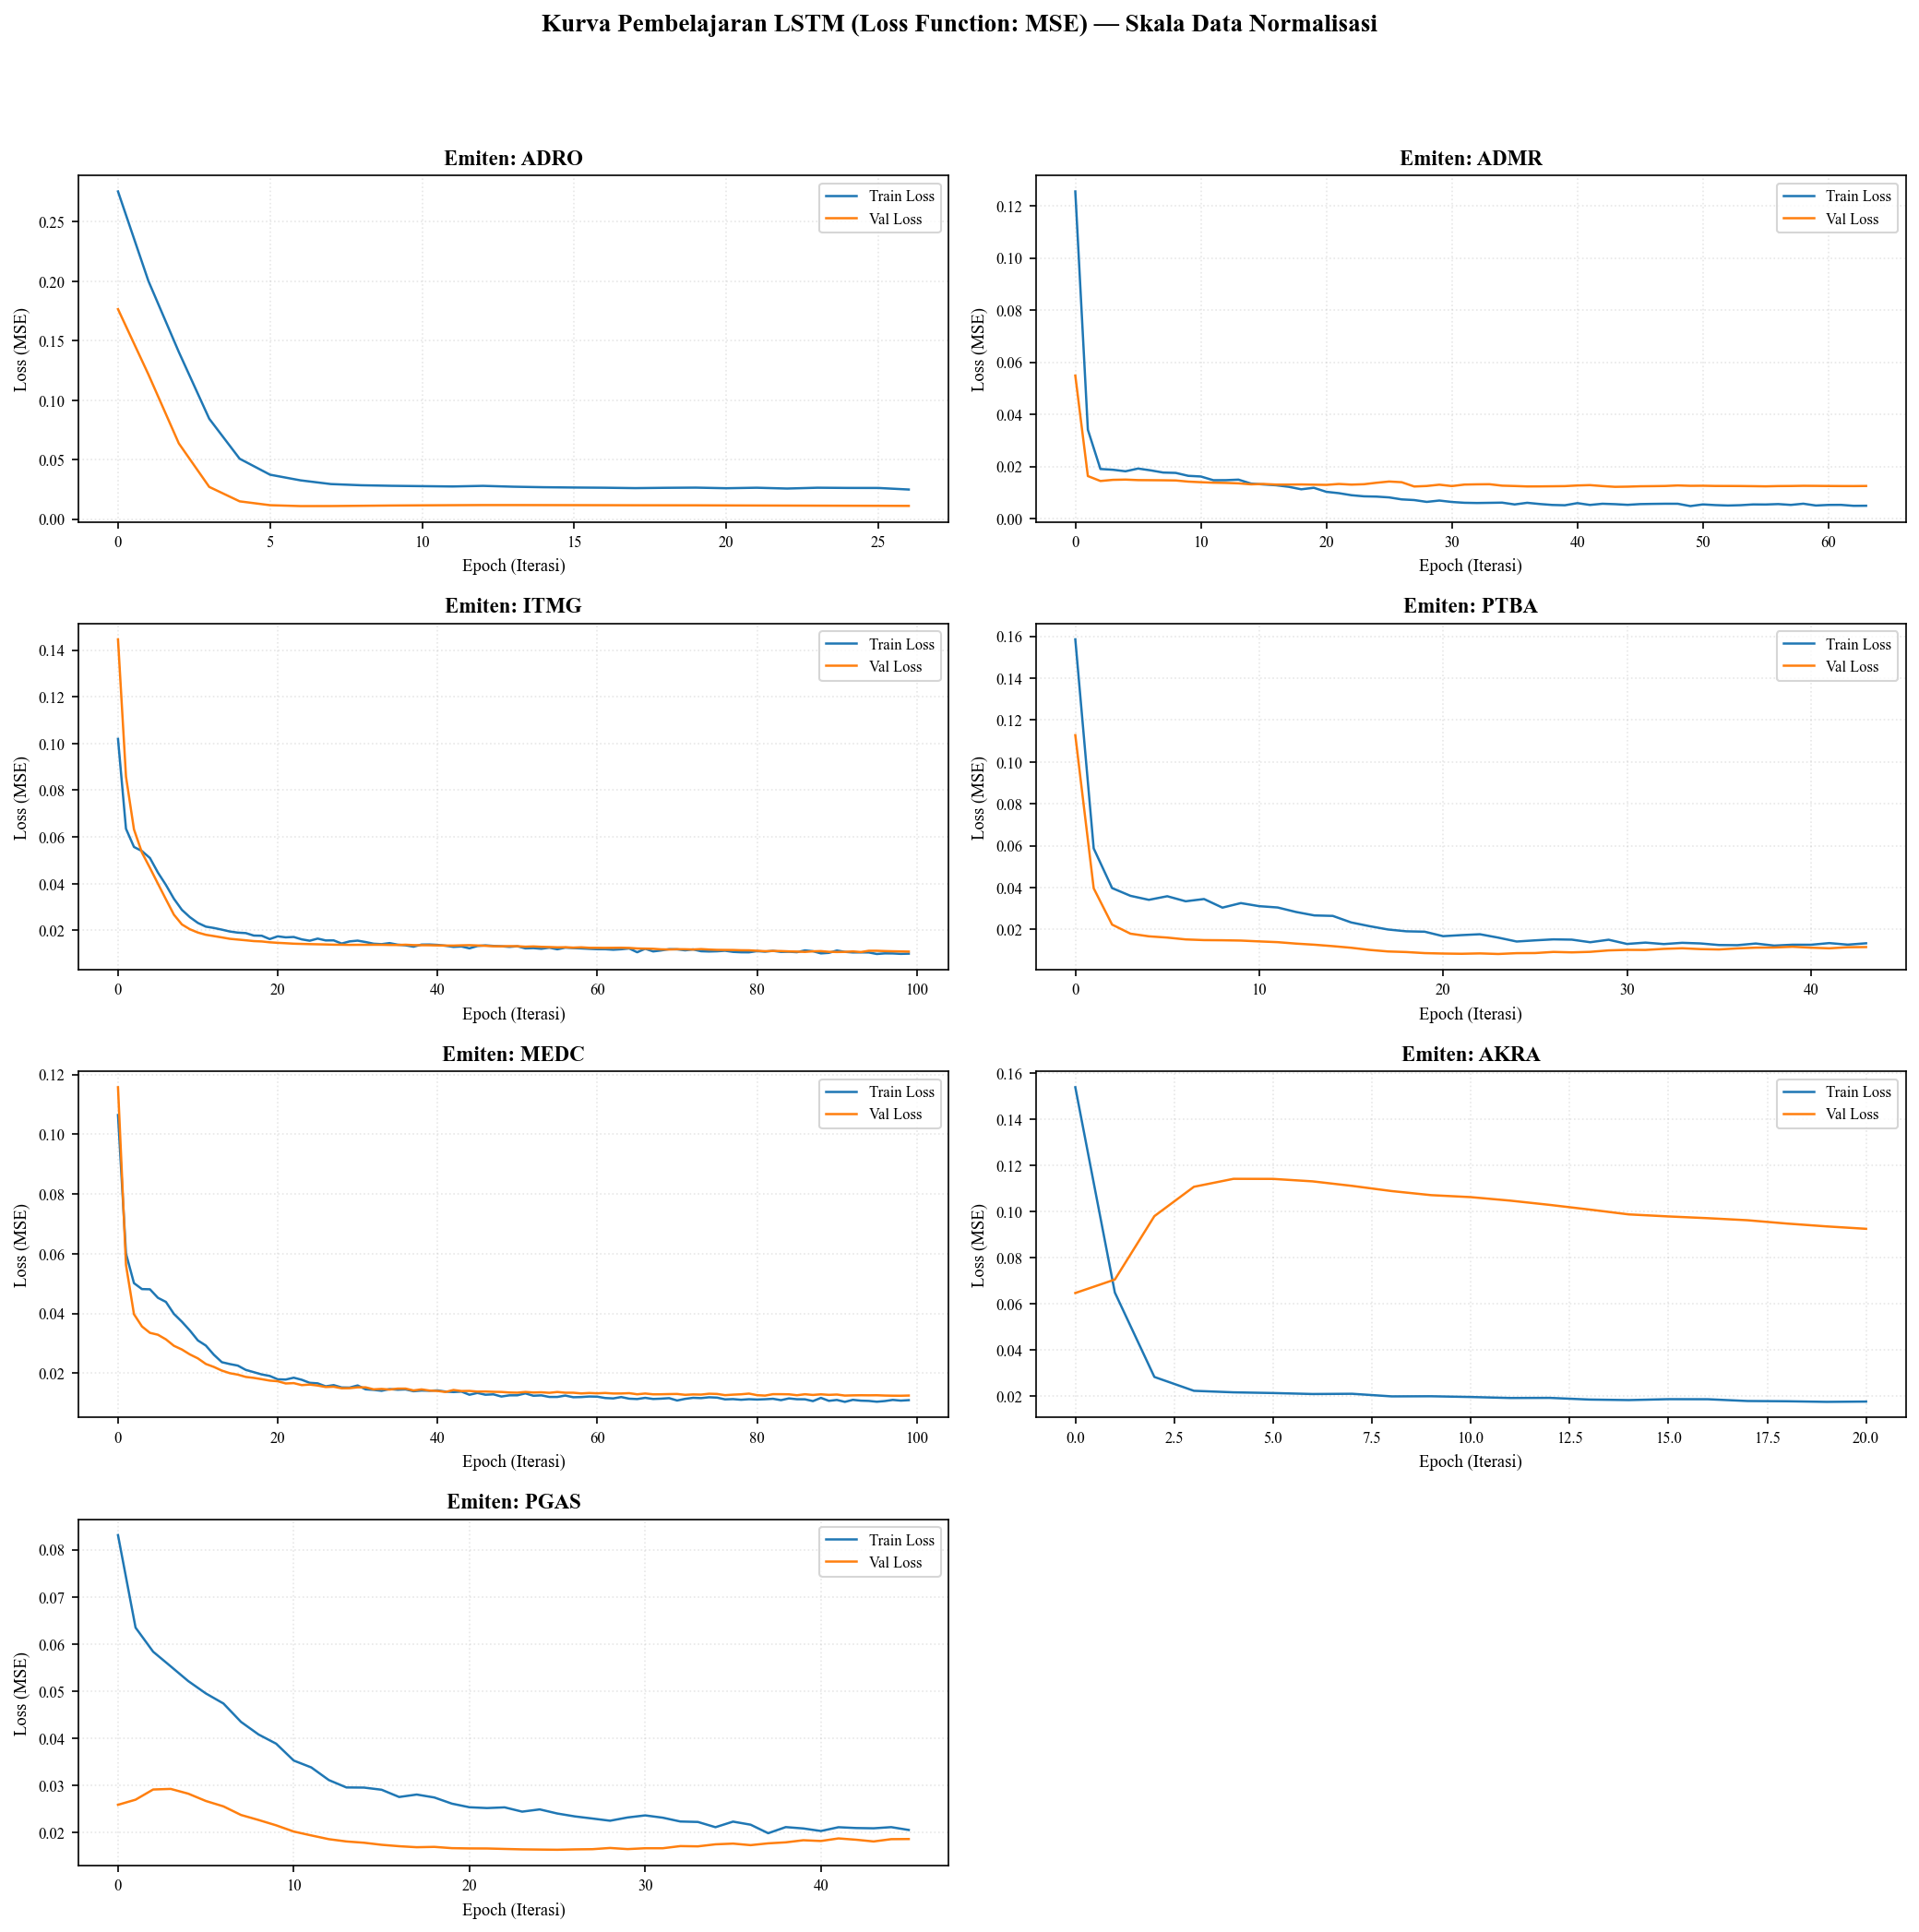

 💾 SUKSES: Grafik kurva pembelajaran berhasil dikunci!
    Lokasi File Gambar: E:\DATA PENTING ILDA NURIDA\DOKUMEN\KULIAH\S2 2025\THESIS\Penelitian\TESIS_PEMODELAN PREDIKSI VOLATILITAS RETURN SAHAM_2026\06_dokumen_tesis\gambar\model\gambar_lstm_learning_curve.png


In [12]:
# ==============================================================================
# CELL — VISUALISASI LEARNING CURVE LSTM (MSE LOSS EVALUATION GRID)
# ==============================================================================

# 1. Tegaskan kembali aturan gaya visualisasi standar naskah akademis (Times New Roman)
plt.rcParams.update({
    'font.family'    : 'Times New Roman',
    'font.size'      : 11,
    'axes.titlesize' : 11,
    'axes.labelsize' : 9,
    'figure.dpi'     : 150,
})

# 2. Filter emiten yang memiliki riwayat history pelatihan valid
emiten_ok = [e for e in URUTAN_EMITEN if e in dict_history]
ncol = 2
nrow = int(np.ceil(len(emiten_ok) / ncol))

# 3. Inisialisasi kanvas multi-grid
fig, axes = plt.subplots(nrow, ncol, figsize=(14, 3.5 * nrow))
axes = np.array(axes).ravel()

# Judul Makro Kurva Eksperimen
fig.suptitle('Kurva Pembelajaran LSTM (Loss Function: MSE) — Skala Data Normalisasi', 
             fontweight='bold', fontsize=13, y=0.995)

# 4. Looping penggambaran grafik loss vs val_loss per emiten
for ax, emiten in zip(axes, emiten_ok):
    h = dict_history[emiten]
    
    # Plot fungsi kerugian data latih dan data validasi internal
    ax.plot(h['loss'], color='#1f77b4', linewidth=1.2, label='Train Loss')
    ax.plot(h['val_loss'], color='#ff7f0e', linewidth=1.2, linestyle='-', label='Val Loss')
    
    # Anotasi judul subplot dan pengaturan label sumbu matematika baku
    ax.set_title(f'Emiten: {emiten}', fontweight='bold')
    ax.set_xlabel('Epoch (Iterasi)')
    ax.set_ylabel('Loss (MSE)')
    
    # Konfigurasi kosmetik grid pendukung teks
    ax.legend(fontsize=8, loc='upper right')
    ax.tick_params(labelsize=8)
    ax.grid(True, alpha=0.3, linestyle=':')

# 5. Nonaktifkan panel ke-8 (Grid sisa pojok kanan bawah kosong karena total 7 emiten)
for ax in axes[len(emiten_ok):]: 
    ax.axis('off')

# Optimasi susunan agar elemen visual tidak saling bertubrukan
plt.tight_layout(rect=[0, 0, 1, 0.96])

# 6. Ekspor Berkas Gambar Resolusi Tinggi ke DIR_GAMBAR Tesis
jalur_simpan_grafik = DIR_GAMBAR / 'gambar_lstm_learning_curve.png'
plt.savefig(jalur_simpan_grafik, dpi=150, bbox_inches='tight')
plt.show()

print('=' * 85)
print(f' 💾 SUKSES: Grafik kurva pembelajaran berhasil dikunci!')
print(f'    Lokasi File Gambar: {jalur_simpan_grafik.resolve()}')
print('=' * 85)


## 📊 CELL 8 — Grafik Aktual vs Prediksi (→ Gambar 4.X)

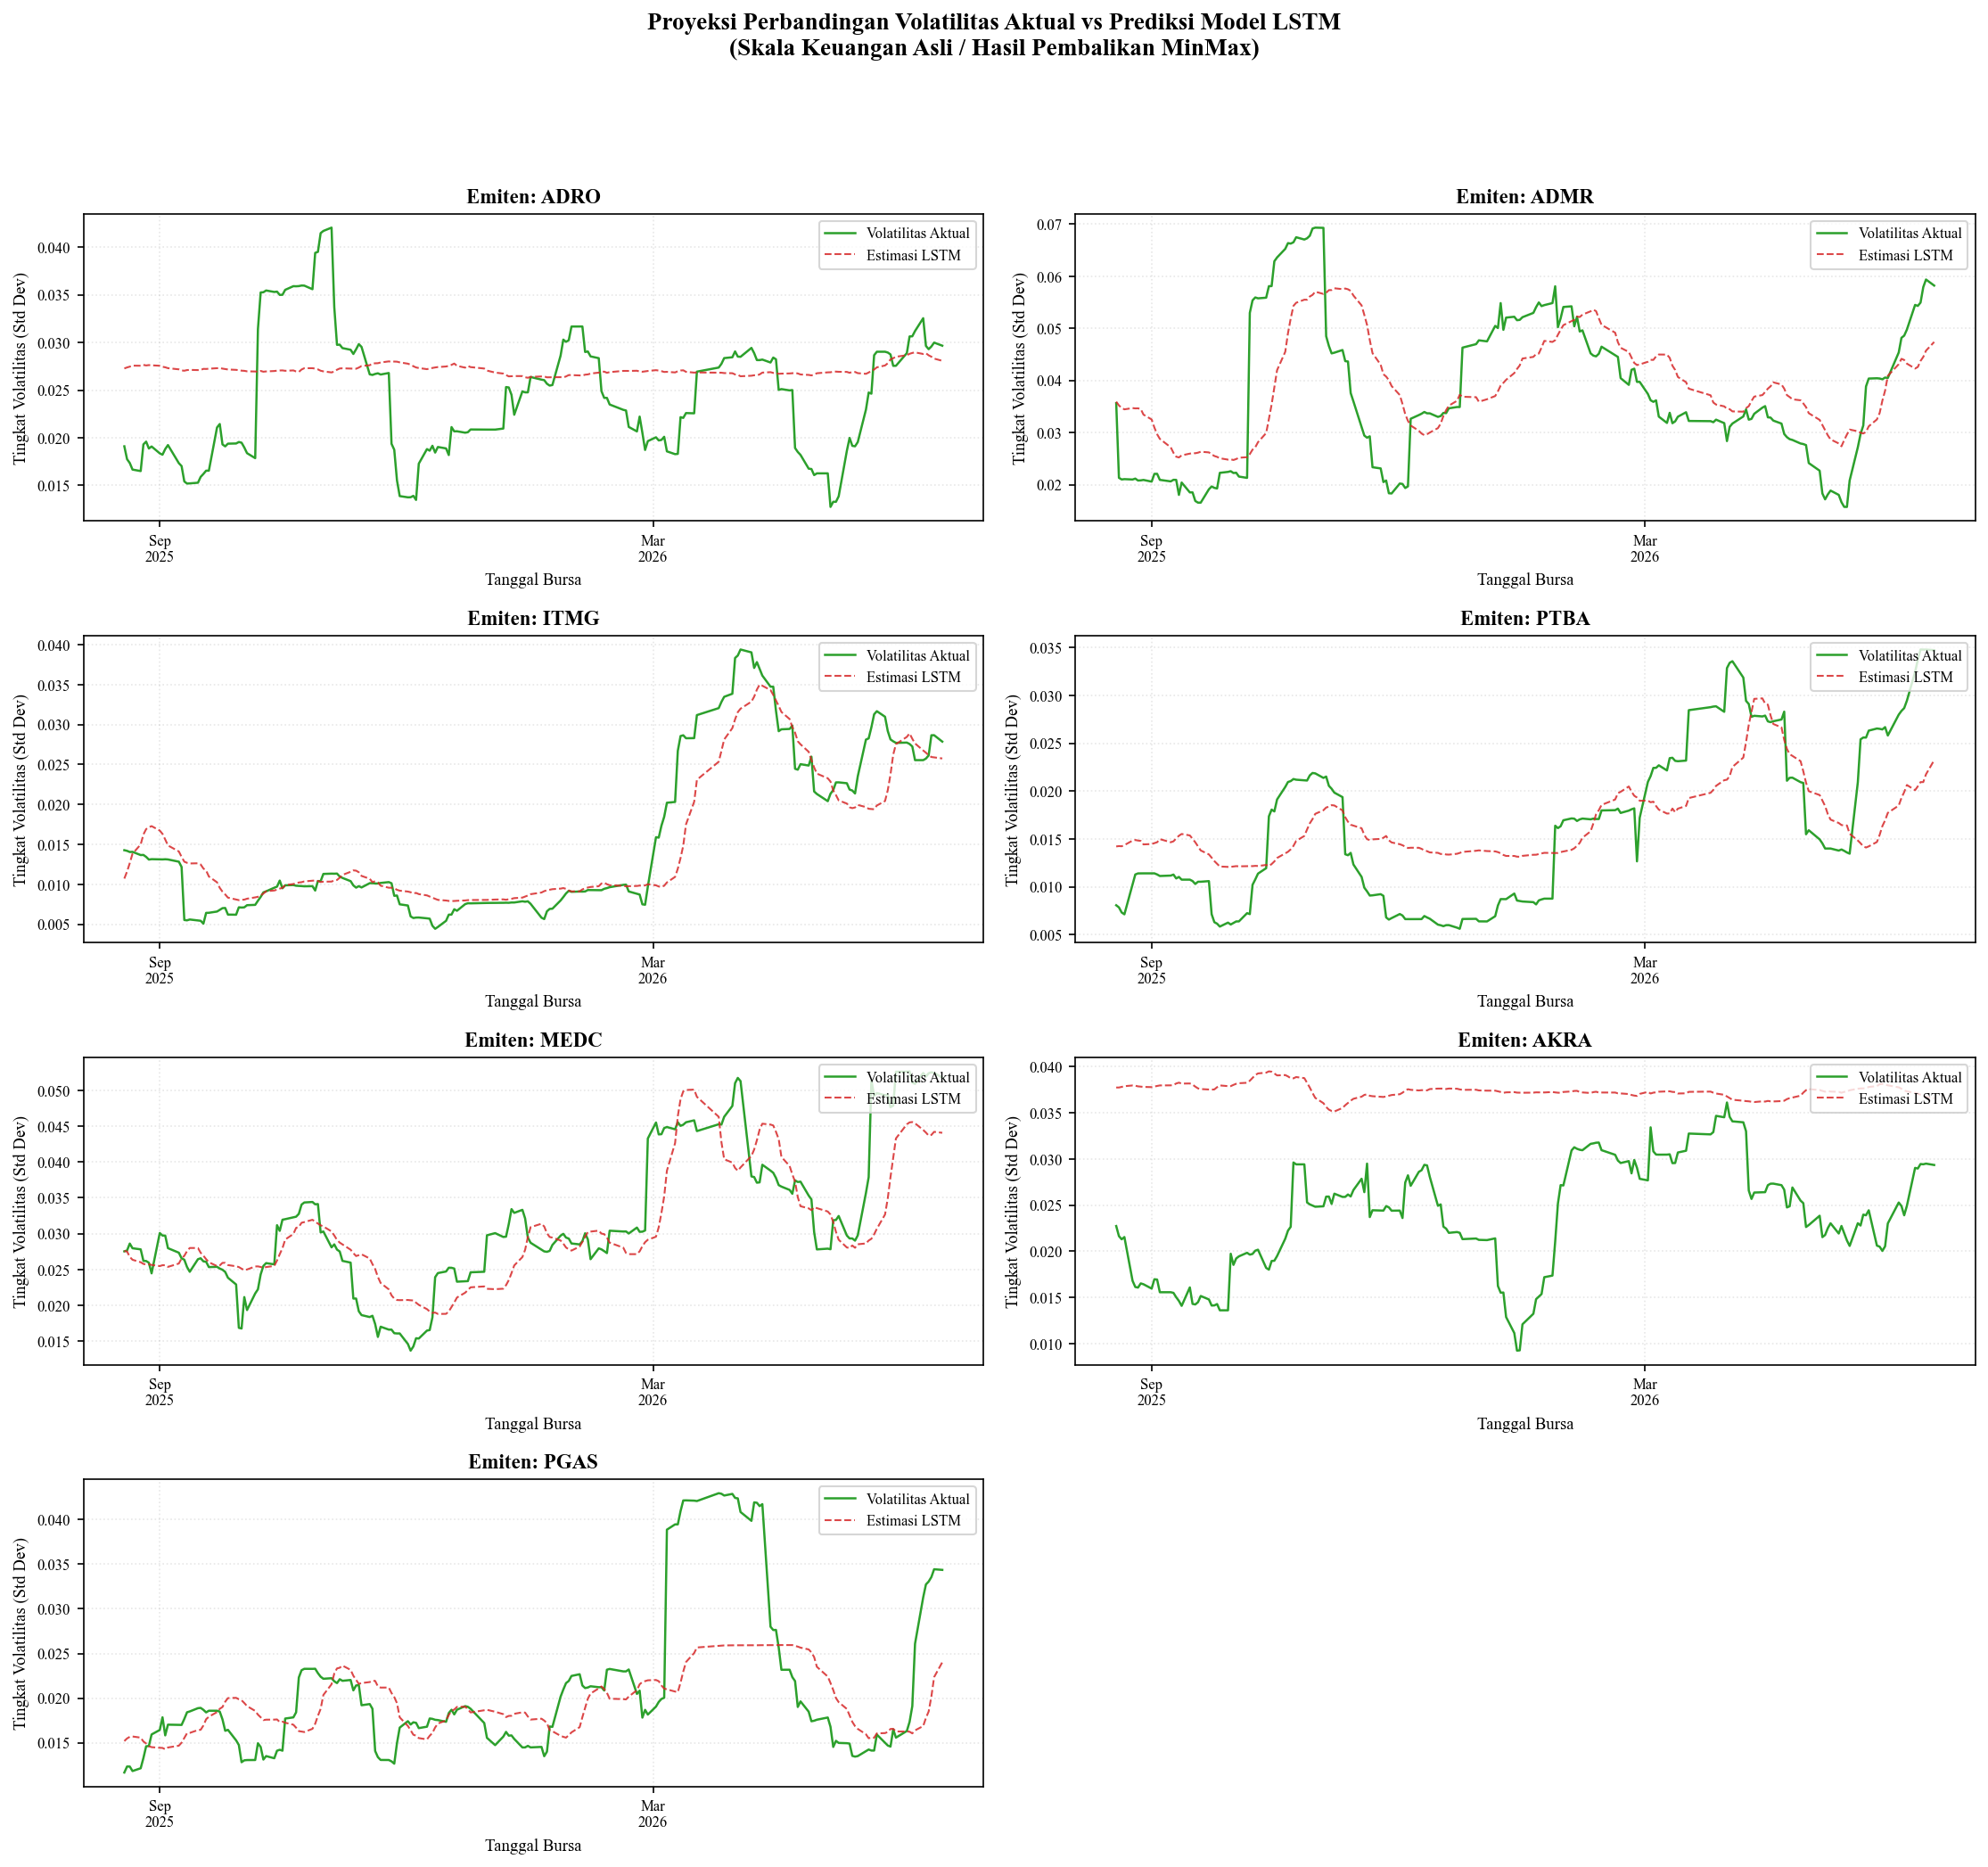

 💾 SUKSES: Grafik perbandingan nilai aktual vs prediksi LSTM berhasil dikunci!
    Lokasi File Gambar: E:\DATA PENTING ILDA NURIDA\DOKUMEN\KULIAH\S2 2025\THESIS\Penelitian\TESIS_PEMODELAN PREDIKSI VOLATILITAS RETURN SAHAM_2026\06_dokumen_tesis\gambar\model\gambar_lstm_prediksi_per_emiten.png


In [13]:
# ==============================================================================
# CELL — VISUALISASI PERBANDINGAN TREN VOLATILITAS AKTUAL VS PREDIKSI LSTM
# ==============================================================================

import matplotlib.dates as mdates

# 1. Tegaskan kembali aturan gaya visualisasi standar naskah akademis (Times New Roman)
plt.rcParams.update({
    'font.family'    : 'Times New Roman',
    'font.size'      : 11,
    'axes.titlesize' : 11,
    'axes.labelsize' : 9,
    'figure.dpi'     : 150,
})

# 2. Filter emiten yang memiliki riwayat komputasi hasil prediksi valid
emiten_ok = [e for e in URUTAN_EMITEN if e in dict_hasil_lstm]
ncol = 2
nrow = int(np.ceil(len(emiten_ok) / ncol))

# 3. Inisialisasi kanvas multi-grid
fig, axes = plt.subplots(nrow, ncol, figsize=(15, 3.5 * nrow))
axes = np.array(axes).ravel()

# Judul Utama Grafik
fig.suptitle('Proyeksi Perbandingan Volatilitas Aktual vs Prediksi Model LSTM\n(Skala Keuangan Asli / Hasil Pembalikan MinMax)', 
             fontweight='bold', fontsize=13, y=0.995)

# 4. Looping penggambaran kurva volatilitas per emiten
for ax, emiten in zip(axes, emiten_ok):
    d = dict_hasil_lstm[emiten].copy()
    
    # [SOLUSI KRITIS] Pastikan kolom Date bertipe datetime murni agar fungsi pencari mdates bekerja
    d['Date'] = pd.to_datetime(d['Date'])
    
    # Plotting kurva volatilitas berbasis tanggal riil bursa
    ax.plot(d['Date'], d['Y_Aktual'], color='#2ca02c', linewidth=1.2, label='Volatilitas Aktual')
    ax.plot(d['Date'], d['Y_Prediksi'], color='#d62728', linewidth=1.0, linestyle='--', alpha=0.85, label='Estimasi LSTM')
    
    # Penataan judul panel, label sumbu, dan ukuran tick angka
    ax.set_title(f'Emiten: {emiten}', fontweight='bold')
    ax.set_xlabel('Tanggal Bursa')
    ax.set_ylabel('Tingkat Volatilitas (Std Dev)')
    
    # [OPTIMALISASI SUMBU X] Atur kerapian visual sumbu tanggal agar tidak bertumpuk
    ax.xaxis.set_major_locator(mdates.MonthLocator(interval=6)) # Tampilkan ticks per 6 bulan
    ax.xaxis.set_major_formatter(mdates.DateFormatter('%b\n%Y')) # Format: Jan 2026
    ax.tick_params(axis='x', labelsize=8)
    ax.tick_params(axis='y', labelsize=8)
    
    # Kosmetik pendukung visualisasi data panel
    ax.legend(fontsize=8, loc='upper right')
    ax.grid(True, alpha=0.3, linestyle=':')

# 5. Nonaktifkan panel ke-8 sisa grid kosong
for ax in axes[len(emiten_ok):]: 
    ax.axis('off')

# Optimasi penataan elemen visual
plt.tight_layout(rect=[0, 0, 1, 0.95])

# 6. Ekspor Gambar Beresolusi Tinggi ke DIR_GAMBAR Tesis
jalur_simpan_prediksi = DIR_GAMBAR / 'gambar_lstm_prediksi_per_emiten.png'
plt.savefig(jalur_simpan_prediksi, dpi=150, bbox_inches='tight')
plt.show()

print('=' * 85)
print(f' 💾 SUKSES: Grafik perbandingan nilai aktual vs prediksi LSTM berhasil dikunci!')
print(f'    Lokasi File Gambar: {jalur_simpan_prediksi.resolve()}')
print('=' * 85)


## 💾 CELL 9 — Simpan Hasil Prediksi

In [14]:
df_all = pd.concat(dict_hasil_lstm.values(), ignore_index=True)
df_all.to_csv(DIR_TABEL / 'hasil_prediksi_lstm.csv', encoding='utf-8-sig', index=False)
print('='*70); print('✅ MODEL LSTM SELESAI')
print(f'  Hasil prediksi : hasil_prediksi_lstm.csv ({len(df_all):,} baris)')
print(f'  Model .keras   : {DIR_MODEL}')
print('  → Lanjut: jalankan EVALUASI_perbandingan.ipynb utk jawab RM-3')
print('='*70)

✅ MODEL LSTM SELESAI
  Hasil prediksi : hasil_prediksi_lstm.csv (1,393 baris)
  Model .keras   : e:\DATA PENTING ILDA NURIDA\DOKUMEN\KULIAH\S2 2025\THESIS\Penelitian\TESIS_PEMODELAN PREDIKSI VOLATILITAS RETURN SAHAM_2026\04_model\lstm
  → Lanjut: jalankan EVALUASI_perbandingan.ipynb utk jawab RM-3
